# Pandas homework

Please use folder source_files folder for source csv files, output_files folder for files that you will export during you homework (tasks ): 

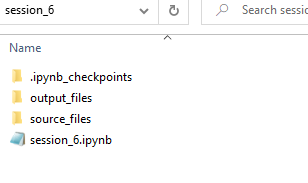

Source_files foder should looks like:

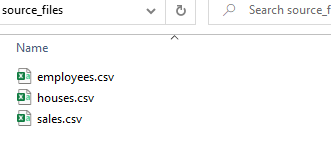

Output_files folder should looks like:
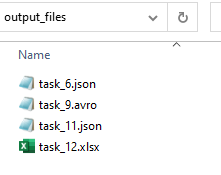

Please do not change test cells, just run them after you write you code and check if the result is correct.

In [71]:
import os
import json
import pandas as pd
import numpy as np
import pandavro as pdx

In [66]:
PATH_TO_SALES = "./source_files/sales.csv"
PATH_TO_HOUSES = "./source_files/houses.csv"
PATH_TO_EMPLOYEES = "./source_files/employees.csv"

### 1. Create 3 Dataframes(sales, houses, employees) for csv files

In [5]:
# Add your code here
sales = pd.read_csv("source_files/sales.csv")
houses = pd.read_csv("source_files/houses.csv")
employees = pd.read_csv("source_files/employees.csv")

In [7]:
assert 993112 == len(sales), (
    "Incorrect size of sales DataFrame"
)
assert 1019875 == len(houses), (
    "Incorrect size of houses DataFrame"
)
assert 870 == len(employees), (
    "Incorrect size of employees DataFrame"
)
assert (['LOCATION_ID', 'HOUSE_ID', 'DATERECORDED', 'BRANCH_ID', 'CUSTOMER_ID',
       'COST', 'SALEAMOUNT', 'PAYMENT_TYPE_ID', 'PAYMENT_TYPE', 'EMP_ID'] == sales.columns).all(), (
    "Incorrect column names for sales DataFrame"
)
assert (['HOUSE_ID', 'HOUSE_NAME', 'HOUSE_CATEGORY_ID', 'HOUSE_CATEGORY',
       'HOUSE_SUBCATEGORY_ID', 'HOUSE_SUBCATEGORY', 'SQUARE', 'PRICE',
       'LOCATION_ID', 'UPDATE_DT'] == houses.columns).all(), (
    "Incorrect column names for houses DataFrame"
)
assert (['EMP_ID', 'EMP_FIRST_NAME', 'EMP_LAST_NAME', 'EMP_GENDER',
       'EMP_DATE_BIRTH', 'EMP_START_DATE', 'EMP_BRANCH'] == employees.columns).all(), (
    "Incorrect column names for employees DataFrame"
)
print("Tests were passed")

Tests were passed


###  2. Extract employee first name/last name from 3 to 10 rows(including) from Employees

In [19]:
# Add your code here
names = employees.loc[3:10, ['EMP_FIRST_NAME', 'EMP_LAST_NAME']]

print(names)

   EMP_FIRST_NAME EMP_LAST_NAME
3          Shelia      Larchier
4           Annie        Jerche
5         Cacilia        Pester
6          Ronica       McAlees
7          Bobina   Hrihorovich
8          Valina      Bestwall
9         Jaynell       Mattedi
10        Andonis        Muress


In [20]:
assert "Shelia" == names.iloc[0]['EMP_FIRST_NAME'], (
    "Incorrect name of first person"
)
assert "Larchier" == names.iloc[0]['EMP_LAST_NAME'], (
    "Incorrect surname of first person"
)
assert "Andonis" == names.iloc[7]['EMP_FIRST_NAME'], (
    "Incorrect name of last person"
)
assert "Muress" == names.iloc[7]['EMP_LAST_NAME'], (
    "Incorrect surname of last person"
)
print("Tests were passed")

Tests were passed


### 3. Get amount of men/women among all employees (Please use function value_counts())

In [26]:
# Add your code here
amount_by_gender = employees['EMP_GENDER'].value_counts()

print(amount_by_gender)

EMP_GENDER
M    436
F    434
Name: count, dtype: int64


In [27]:
assert (amount_by_gender.index[0] == "M") and (amount_by_gender[0] == 436), (
    "Incorrect number of men"
)
assert (amount_by_gender.index[1] == "F") and (amount_by_gender[1] == 434), (
    "Incorrect number of women"
)
print("Tests were passed")

Tests were passed


### 4. Fill empty cells by 0 in column “square” in houses dataframe

In [29]:
# Add you code here (change 'houses' DataFrame directly)
houses['SQUARE'] = houses['SQUARE'].fillna(0)

In [30]:
assert len(houses[houses["SQUARE"].isna()]) == 0, (
    "There are empty cells on square columns"
)
print("Test was passed")

Test was passed


### 5. Create new column “UNIT_PRICE” for price/1m2 (Please use the following formula: price/square) + round the result to 2 digits after point. Use -1 for "UNIT_PRICE" in case square = 0

In [34]:
# Add you code here (add new column to 'houses' DataFrame directly)
houses['UNIT_PRICE'] = np.where(houses['SQUARE'] == 0, -1, (houses['PRICE'] / houses['SQUARE'].round(2)))

print(houses[['PRICE', 'SQUARE', 'UNIT_PRICE']].head())

    PRICE  SQUARE  UNIT_PRICE
0   88660    44.0      2015.0
1  141848    68.0      2086.0
2  139035    69.0      2015.0
3  122915    61.0      2015.0
4  153140    76.0      2015.0


In [32]:
assert ('UNIT_PRICE' in houses) == True, (
    "UNIT_PRICE column is missed in houses DataFrame"
)
assert houses['UNIT_PRICE'].iloc[0] == 2015, (
    "UNIT_PRICE column is calculated incorrectly in houses DataFrame"
)
assert houses['UNIT_PRICE'].iloc[31] == 2015.00, (
    "Incorrect rounding for UNIT_PRICE column in houses DataFrame"
)
assert houses['UNIT_PRICE'].iloc[20] == -1, (
    "Incorrect value for UNIT_PRICE column in houses DataFrame in case SQUARE column = 0"
)
print("Tests were passed")

Tests were passed


### 6. Sort houses dataframe by price descending; put the result to json file ('output_files/task_6.json').

In [38]:
# Add you code here
houses = houses.sort_values(by='PRICE', ascending=False)

houses.to_json('output_files/task_6.json', orient='records', indent=4)

print("File successfully saved to output_files/task_6.json")

File successfully saved to output_files/task_6.json


In [39]:
assert houses["PRICE"].iloc[-1] == 30400, (
    "Incorrect sorting"
)
assert houses["PRICE"].iloc[0] == 558600, (
    "Incorrect sorting"
)
assert os.path.exists('./output_files/task_6.json') == True, (
    "No task_6.json file in the output_files folder"
)
print("Tests were passed")

Tests were passed


### 7. Please filter employees dataframe and find how much women with name ‘Vera’ we have

In [40]:
# Add you code here
employees_filtered = employees[
    (employees['EMP_FIRST_NAME'] == 'Vera') &
    (employees['EMP_GENDER'] == 'F')
]

vera_count = len(employees_filtered)

print(f"Number of women named Vera: {vera_count}")
print(employees_filtered)

Number of women named Vera: 1
     EMP_ID EMP_FIRST_NAME EMP_LAST_NAME EMP_GENDER EMP_DATE_BIRTH  \
446     428           Vera          Eede          F      27-OCT-76   

    EMP_START_DATE  EMP_BRANCH  
446      29-JUL-11      3000.0  


In [41]:
assert len(employees_filtered) == 1, (
    "Incorrect number of women"
)
print("Test was passed")

Test was passed


### 8. Please count (size()) how many houses do we have with square >= 100 m2, group by category and subcategory.


In [42]:
#Add you code here
df = houses[houses['SQUARE'] >= 100].groupby(['HOUSE_CATEGORY', 'HOUSE_SUBCATEGORY']).size()

In [43]:
assert df[0] == 1150, (
    "Incorrect count"
)
assert df[1] == 29644, (
    "Incorrect count"
)
assert df[2] == 70076, (
    "Incorrect count"
)
assert df[3] == 86618, (
    "Incorrect count"
)
assert df.index[0]==('non-residential','office'), (
    "Incorrect group by columns"
)
assert df.index[1]==('non-residential','stock'), (
    "Incorrect group by columns"
)
assert df.index[2]==('residential','duplex house'), (
    "Incorrect group by columns"
)
assert df.index[3]==('residential','single-family house'), (
    "Incorrect group by columns"
)
print("Tests were passed")

Tests were passed


### 9. Put the result from task 7 to file .avro  ('output_files/task_9.avro')

In [52]:
#Add your code here
pdx.to_avro('output_files/task_9.avro', employees_filtered)

print("File successfully saved to output_files/task_9.avro")

File successfully saved to output_files/task_9.avro


In [53]:
assert os.path.exists('./output_files/task_9.avro') == True, (
    "No task_9.avro file in the output_files folder"
)
print("Tests were passed")

Tests were passed


### 10. Please update “SALESAMOUNT” column according to the following rule “SALESAMOUNT” = “SALESAMOUNT” + avg value of SALESAMOUNT*0.02 (Please try to use apply and lambda for it)

In [69]:
# Add your code here
avg_sales = sales['SALEAMOUNT'].mean()

sales['SALEAMOUNT'] = sales['SALEAMOUNT'].apply(lambda x: x + (avg_sales * 0.02))

print(sales['SALEAMOUNT'].head())

0     65734.250029
1     80570.250029
2    149909.250029
3    124315.250029
4    122967.250029
Name: SALEAMOUNT, dtype: float64


In [70]:
assert sales['SALEAMOUNT'][0] == 52000.740744939336, (
    "Value in SALESAMOUNT column is incorrect after update"
)
print("Test was passed")

AssertionError: Value in SALESAMOUNT column is incorrect after update

### 11. Please find all houses that are unsold yet (exists in houses but does not exist in sales, join by house_id). Put house ids to .json ('output_files/task_11.json'). Put result list of unique house names into house_ids_available list

In [74]:
# Add your code here
merged = houses.merge(sales, on='HOUSE_ID', how='left', indicator=True)

unsold_houses = merged[merged['_merge'] == 'left_only']

unsold_ids = unsold_houses['HOUSE_ID'].unique().tolist()

with  open("output_files/task_11.json", 'w') as f:
    json.dump(unsold_ids, f, indent=4)

# Put result list of unique house names into house_ids_available list
house_ids_available = unsold_ids

print(f"Number of unsold houses found: {len(unsold_ids)}")
house_ids_available

Number of unsold houses found: 26775


[948530,
 837006,
 939634,
 984054,
 975729,
 934216,
 105481,
 822985,
 844788,
 886509,
 961037,
 996741,
 916847,
 938210,
 78426,
 890737,
 1016141,
 955050,
 965074,
 983053,
 884118,
 893394,
 878656,
 818351,
 940871,
 1008202,
 917505,
 919163,
 976534,
 918291,
 956456,
 987755,
 981926,
 816967,
 921133,
 1014088,
 902193,
 883842,
 1004508,
 943298,
 875227,
 845510,
 845325,
 1002985,
 840964,
 830024,
 828718,
 1011721,
 913697,
 986360,
 66147,
 944145,
 875952,
 853979,
 862607,
 912594,
 819447,
 827465,
 839358,
 825918,
 941407,
 999842,
 960204,
 957327,
 1007373,
 977755,
 854438,
 918389,
 861305,
 886462,
 837065,
 919150,
 851616,
 841778,
 900756,
 983058,
 951558,
 1008543,
 1019433,
 1009043,
 1015020,
 906081,
 877137,
 984416,
 974352,
 823244,
 832352,
 842638,
 823695,
 854501,
 874039,
 976549,
 853819,
 874444,
 945123,
 831750,
 885223,
 852262,
 860440,
 958364,
 830107,
 932650,
 78859,
 972116,
 838406,
 990072,
 818902,
 992846,
 1013030,
 823232,
 

In [75]:
assert os.path.exists('./output_files/task_11.json') == True, (
    "No task_11.json file in the output_files folder"
)
assert type(house_ids_available) == list, (
    "house_ids_available is not list"
)
assert len(house_ids_available) == 26775, (
    "Incorrect number of houses"
)
assert (917505 in house_ids_available) and (131073 in house_ids_available), (
    "Incorrect values in house_ids_available list"
)
print("Tests were passed")

Tests were passed


### *12. Please find sum of sales_amount by each employee, put the result to excel ('output_files/task_12.xlsx') (emp_id, emp_first_name, emp_last_name, sum(sales_amount)) and mark employees who have less than average sales_amount with red.

In [77]:
# This task is optional
# Add you code here
merged_sales = sales.merge(employees, on='EMP_ID', how='inner')

emp_sales = merged_sales.groupby(['EMP_ID', 'EMP_FIRST_NAME', 'EMP_LAST_NAME'], as_index=False)['SALEAMOUNT'].sum()

emp_sales = emp_sales.rename(columns={'SALEAMOUNT': 'sum(sales_amount)'})

overall_avg = emp_sales['sum(sales_amount)'].mean()

file_path = 'output_files/task_12.xlsx'

with pd.ExcelWriter(file_path, engine='openpyxl') as writer:
    emp_sales.to_excel(writer, sheet_name='Sales Summary', index=False)

    workbook = writer.book
    worksheet = writer.sheets['Sales Summary']

    from openpyxl.styles import PatternFill

    red_fill = PatternFill(start_color='FFC7CE', end_color='FFC7CE', fill_type='solid')

    for row in range(2, worksheet.max_row + 1):
        cell_value = worksheet.cell(row=row, column=4).value
        if cell_value is not None and cell_value < overall_avg:
            # Highlight the entire row in red
            for col in range(1, 5):
                worksheet.cell(row=row, column=col).fill = red_fill

print(f"Excel file successfully generated at {file_path}")

Excel file successfully generated at output_files/task_12.xlsx
